In [18]:
!pip install shap lime -q

SHAP vs LIME: Do explanation methods agree? (Heart Disease dataset).

loading the dataset

In [19]:
import pandas as pd

url = "https://raw.githubusercontent.com/mrdbourke/zero-to-mastery-ml/master/data/heart-disease.csv"
df = pd.read_csv(url)

print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [20]:
df.info()
df["target"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


,count
target,
1,165
0,138


No missing data (all 303 rows have values in every column)  no cleanup needed
Balanced target: 165 people with heart disease, 138 without. That's roughly 54%/46% nicely balanced, not lopsided. This means accuracy will actually be a meaningful metric later (with a lopsided dataset, accuracy can be misleading).


lets split the data and train our model


In [21]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler


X=df.drop("target",axis=1)
y=df["target"]

X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

print(X_train.shape,X_test.shape)

#Random Forest
rf=RandomForestClassifier(random_state=42)
rf.fit(X_train,y_train)
rf_pred=rf.predict(X_test)
print("Random Forest Accuracy: ",accuracy_score(y_test,rf_pred))


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#LogisticRegression
lr=LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled,y_train)
lr_pred=lr.predict(X_test_scaled)
print("Logistic Regression Accuracy: ",accuracy_score(y_test,lr_pred))



(242, 13) (61, 13)
Random Forest Accuracy:  0.8360655737704918
Logistic Regression Accuracy:  0.8524590163934426


testing on random forest


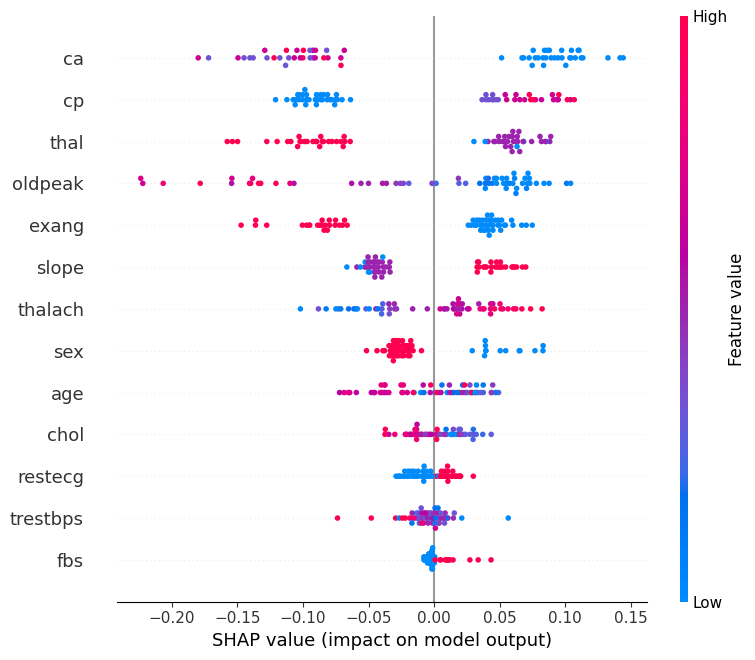

In [22]:
import shap

#creating shap explainer for random forest
explainer_rf=shap.TreeExplainer(rf)
shap_values_rf=explainer_rf.shap_values(X_test)

#summary plot to show which features matter most overally
shap.summary_plot(shap_values_rf[:,:,1],X_test)



In [23]:
from lime.lime_tabular import LimeTabularExplainer

explainer_lime=LimeTabularExplainer(
    X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=["No Disease","Disease"],
    mode="classification"
)
#Explain one specific patient(test row index 0)

exp=explainer_lime.explain_instance(
    X_test.values[0],
    rf.predict_proba,
    num_features=13
)

exp.show_in_notebook(show_table=True)

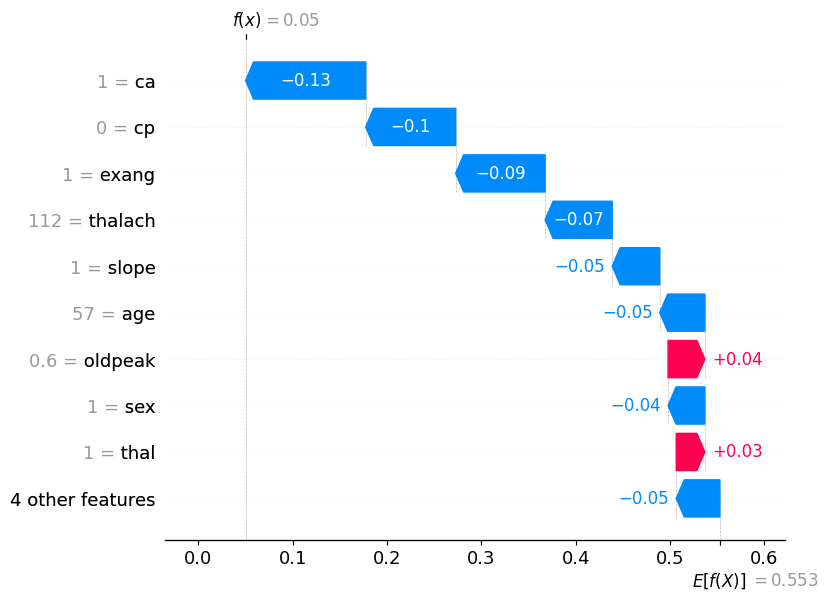

In [24]:
shap.plots.waterfall(shap.Explanation(
    values=shap_values_rf[0,:,1],
    base_values=explainer_rf.expected_value[1],
    data=X_test.iloc[0],
    feature_names=X_test.columns.tolist()
))

Testing on logistic Regression

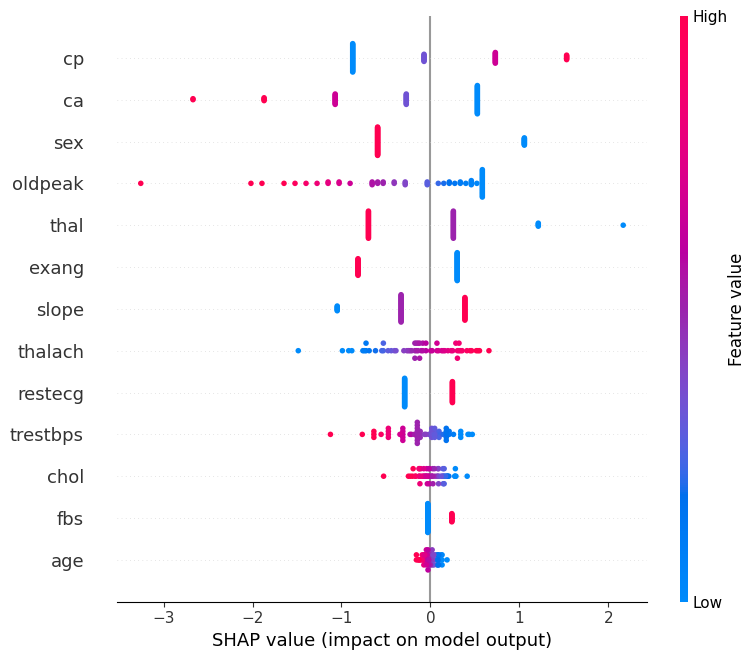

In [25]:
explainer_lr = shap.LinearExplainer(lr, X_train_scaled)
shap_values_lr = explainer_lr.shap_values(X_test_scaled)

shap.summary_plot(shap_values_lr, X_test_scaled, feature_names=X_train.columns.tolist())

In [26]:
explainer_lime_lr = LimeTabularExplainer(
    X_train_scaled,
    feature_names=X_train.columns.tolist(),
    class_names=['No Disease', 'Disease'],
    mode='classification'
)

exp_lr = explainer_lime_lr.explain_instance(
    X_test_scaled[0],
    lr.predict_proba,
    num_features=13
)

exp_lr.show_in_notebook(show_table=True)

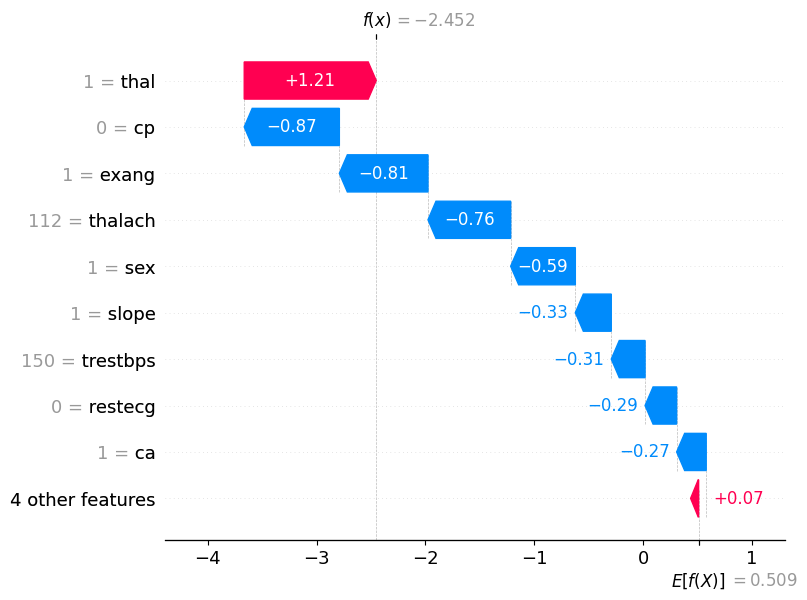

In [27]:
shap.plots.waterfall(shap.Explanation(
    values=shap_values_lr[0],
    base_values=explainer_lr.expected_value,
    data=X_test.iloc[0],
    feature_names=X_test.columns.tolist()
))

In [28]:
#Automating comparison across multiple patients
import numpy as np

def get_lime_top_features(explainer, instance, predict_fn, n=5):
    exp = explainer.explain_instance(instance, predict_fn, num_features=13)
    # exp.as_list() returns [(feature_description, weight), ...] sorted by importance
    top = exp.as_list()[:n]
    # extract just the feature name (LIME's descriptions include ranges, e.g. "ca <= 1.00")
    feature_names = X_train.columns.tolist()
    top_features = []
    for desc, weight in top:
        for fname in feature_names:
            if fname in desc:
                top_features.append(fname)
                break
    return top_features

def get_shap_top_features(shap_row, feature_names, n=5):
    # shap_row = array of SHAP values for one patient
    idx_sorted = np.argsort(-np.abs(shap_row))[:n]
    return [feature_names[i] for i in idx_sorted]

# Compare for patients 0-4, Random Forest
print("=== Random Forest: SHAP vs LIME top-5 overlap ===")
for i in range(5):
    shap_top = get_shap_top_features(shap_values_rf[i,:,1], X_test.columns.tolist())
    lime_top = get_lime_top_features(explainer_lime, X_test.iloc[i].values, rf.predict_proba)
    overlap = len(set(shap_top) & set(lime_top))
    print(f"Patient {i}: SHAP={shap_top} | LIME={lime_top} | Overlap={overlap}/5")

=== Random Forest: SHAP vs LIME top-5 overlap ===
Patient 0: SHAP=['ca', 'cp', 'exang', 'thalach', 'slope'] | LIME=['ca', 'thal', 'cp', 'exang', 'slope'] | Overlap=4/5
Patient 1: SHAP=['ca', 'cp', 'thal', 'oldpeak', 'trestbps'] | LIME=['ca', 'thal', 'exang', 'slope', 'sex'] | Overlap=2/5
Patient 2: SHAP=['ca', 'thal', 'cp', 'age', 'oldpeak'] | LIME=['ca', 'thal', 'exang', 'cp', 'slope'] | Overlap=3/5
Patient 3: SHAP=['exang', 'cp', 'thal', 'ca', 'slope'] | LIME=['oldpeak', 'ca', 'thal', 'cp', 'exang'] | Overlap=4/5
Patient 4: SHAP=['ca', 'cp', 'sex', 'slope', 'thal'] | LIME=['ca', 'thal', 'exang', 'cp', 'slope'] | Overlap=4/5


In [29]:
overlaps_rf = []
for i in range(len(X_test)):
    shap_top = get_shap_top_features(shap_values_rf[i,:,1], X_test.columns.tolist())
    lime_top = get_lime_top_features(explainer_lime, X_test.iloc[i].values, rf.predict_proba)
    overlap = len(set(shap_top) & set(lime_top))
    overlaps_rf.append(overlap)

print("Average overlap (Random Forest):", np.mean(overlaps_rf), "out of 5")
print("All overlaps:", overlaps_rf)

Average overlap (Random Forest): 3.8524590163934427 out of 5
All overlaps: [4, 2, 3, 4, 4, 4, 4, 5, 4, 4, 4, 4, 2, 5, 3, 3, 2, 4, 4, 5, 4, 4, 4, 5, 4, 3, 3, 4, 5, 4, 4, 4, 4, 5, 3, 4, 4, 4, 4, 3, 4, 3, 4, 4, 4, 4, 4, 3, 4, 5, 4, 4, 4, 3, 3, 4, 4, 4, 4, 5, 4]


In [30]:
overlaps_lr = []
for i in range(len(X_test_scaled)):
    shap_top = get_shap_top_features(shap_values_lr[i], X_train.columns.tolist())
    lime_top = get_lime_top_features(explainer_lime_lr, X_test_scaled[i], lr.predict_proba)
    overlap = len(set(shap_top) & set(lime_top))
    overlaps_lr.append(overlap)

print("Average overlap (Logistic Regression):", np.mean(overlaps_lr), "out of 5")
print("All overlaps:", overlaps_lr)

Average overlap (Logistic Regression): 3.1147540983606556 out of 5
All overlaps: [3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 3, 3, 2, 2, 3, 4, 3, 3, 3, 4, 3, 3, 4, 3, 3, 2, 2, 3, 3, 4, 3, 3, 3, 5, 3, 2, 4, 2, 2, 4, 4, 3, 3, 3, 4, 3, 3, 3, 4, 4, 3, 3, 3, 3, 3, 3, 3, 4, 3]


In [31]:
from scipy import stats

statistic, p_value = stats.mannwhitneyu(overlaps_rf, overlaps_lr, alternative='two-sided')

print("Mann-Whitney U statistic:", statistic)
print("p-value:", p_value)

if p_value < 0.05:
    print("The difference IS statistically significant (p < 0.05)")
else:
    print("The difference is NOT statistically significant (p >= 0.05)")

Mann-Whitney U statistic: 2903.0
p-value: 6.960308027642102e-09
The difference IS statistically significant (p < 0.05)


In [32]:
from scipy import stats

stat, p_paired = stats.wilcoxon(overlaps_rf, overlaps_lr)

print("Wilcoxon statistic:", stat)
print("p-value:", p_paired)
print("Mean RF overlap:", np.mean(overlaps_rf), "| Mean LR overlap:", np.mean(overlaps_lr))

Wilcoxon statistic: 87.5
p-value: 4.400226000908825e-07
Mean RF overlap: 3.8524590163934427 | Mean LR overlap: 3.1147540983606556


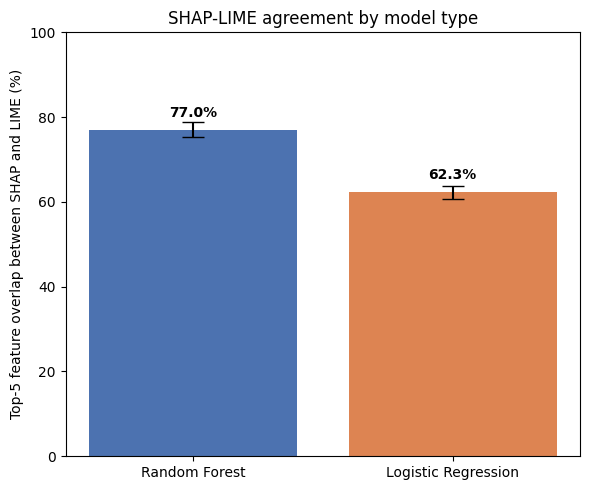

In [33]:
import matplotlib.pyplot as plt

means = [np.mean(overlaps_rf) / 5 * 100, np.mean(overlaps_lr) / 5 * 100]
# standard error = how much the average could wobble, shown as the small error bar
sems = [stats.sem(overlaps_rf) / 5 * 100, stats.sem(overlaps_lr) / 5 * 100]

plt.figure(figsize=(6, 5))
bars = plt.bar(["Random Forest", "Logistic Regression"], means,
               yerr=sems, capsize=8, color=["#4C72B0", "#DD8452"])

for bar, m in zip(bars, means):
    plt.text(bar.get_x() + bar.get_width() / 2, m + 3, f"{m:.1f}%",
             ha="center", fontweight="bold")

plt.ylabel("Top-5 feature overlap between SHAP and LIME (%)")
plt.title("SHAP-LIME agreement by model type")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("shap_lime_overlap.png", dpi=300)
plt.show()

RF overlap: 78.0 %
LR overlap: 62.6 %
Wilcoxon p-value: 4.2683880631323767e-08


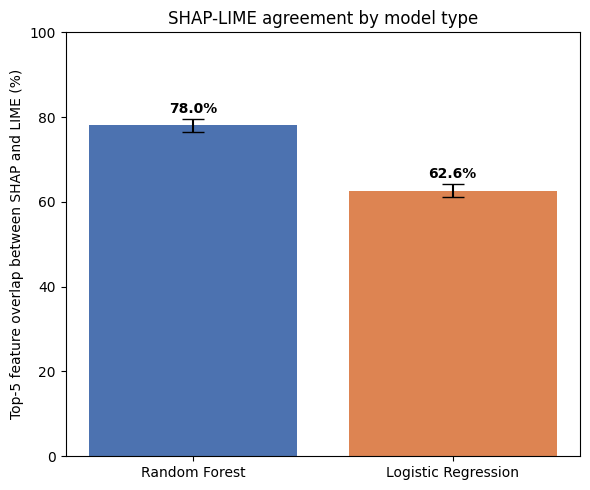

In [34]:
import warnings
warnings.filterwarnings("ignore")   # hides the harmless feature-name warning spam

from scipy import stats
import matplotlib.pyplot as plt

# LIME explainers, now with a fixed seed so results are reproducible
explainer_lime = LimeTabularExplainer(
    X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=["No Disease", "Disease"],
    mode="classification",
    random_state=42
)
explainer_lime_lr = LimeTabularExplainer(
    X_train_scaled,
    feature_names=X_train.columns.tolist(),
    class_names=["No Disease", "Disease"],
    mode="classification",
    random_state=42
)

# Random Forest: SHAP vs LIME overlap for all 61 test patients
overlaps_rf = []
for i in range(len(X_test)):
    shap_top = get_shap_top_features(shap_values_rf[i, :, 1], X_test.columns.tolist())
    lime_top = get_lime_top_features(explainer_lime, X_test.iloc[i].values, rf.predict_proba)
    overlaps_rf.append(len(set(shap_top) & set(lime_top)))

# Logistic Regression: same thing
overlaps_lr = []
for i in range(len(X_test_scaled)):
    shap_top = get_shap_top_features(shap_values_lr[i], X_train.columns.tolist())
    lime_top = get_lime_top_features(explainer_lime_lr, X_test_scaled[i], lr.predict_proba)
    overlaps_lr.append(len(set(shap_top) & set(lime_top)))

# Final numbers
print("RF overlap:", round(np.mean(overlaps_rf) / 5 * 100, 1), "%")
print("LR overlap:", round(np.mean(overlaps_lr) / 5 * 100, 1), "%")

stat, p_paired = stats.wilcoxon(overlaps_rf, overlaps_lr)
print("Wilcoxon p-value:", p_paired)

# Chart
means = [np.mean(overlaps_rf) / 5 * 100, np.mean(overlaps_lr) / 5 * 100]
sems = [stats.sem(overlaps_rf) / 5 * 100, stats.sem(overlaps_lr) / 5 * 100]

plt.figure(figsize=(6, 5))
bars = plt.bar(["Random Forest", "Logistic Regression"], means,
               yerr=sems, capsize=8, color=["#4C72B0", "#DD8452"])
for bar, m in zip(bars, means):
    plt.text(bar.get_x() + bar.get_width() / 2, m + 3, f"{m:.1f}%",
             ha="center", fontweight="bold")
plt.ylabel("Top-5 feature overlap between SHAP and LIME (%)")
plt.title("SHAP-LIME agreement by model type")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("shap_lime_overlap.png", dpi=300)
plt.show()